# Directed Sheaf Neural Networks

Many relations have a direction: a paper *cites* another, money *flows* from one account to another, a neuron *excites* its target. Treating such graphs as undirected throws that information away. This notebook studies two ways of keeping it in a sheaf model:
* the repository's **Directed NSD** (`DIRECTED_NSD`), which aggregates forward and reverse neighbours separately, each with its own restriction maps and normalization, and blends them with a weight $\alpha$ (in the spirit of Dir-GNN);
* the **Directed Sheaf Laplacian** of *Sheaves Reloaded* (Fiorini et al., 2025, the DSNN model), which encodes direction in the *phase* of complex-valued restriction maps and generalizes the magnetic Laplacian.

### What You Will Learn
* Why direction is information, and why an arbitrary orientation in the undirected coboundary does not model it.
* How the repository's directed layer computes its two normalized aggregations, and what $\alpha$ controls.
* How complex phases turn a directed graph into a Hermitian (and therefore well-behaved) Laplacian, and why direction only changes its spectrum through **cycles**.
* A toy task where only the predecessor of a node is informative. We use it to find out what $\alpha$ does (and does not) control, and to probe the trained model by reversing the edges.

### Notebook Roadmap
1. **Motivate** directed message passing.
2. **Formalize** the repository's directed operator and the complex-valued directed sheaf Laplacian.
3. **Build** a directed toy task where only in-neighbours carry the label.
4. **Train** directed and undirected sheaf models.
5. **Interpret** the role of $\alpha$, a learnable direction weight, and an edge-reversal test.

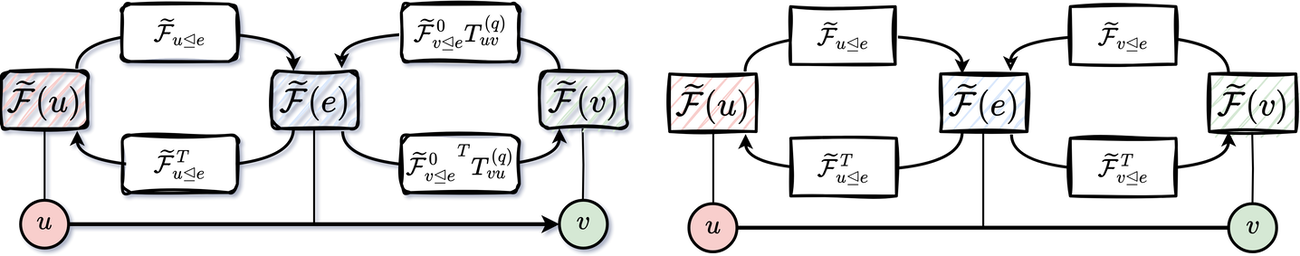

*The complex-valued restriction maps of a Directed Cellular Sheaf for (a) a directed edge and (b) an undirected edge. For a directed edge, the map of one endpoint is multiplied by a phase T^(q), which encodes the direction; for an undirected edge, the phase is 1 and the ordinary real sheaf is recovered.*

<sub>Source: Fiorini et al. (2025), *Sheaves Reloaded: A Directional Awakening*, [arXiv:2506.02842](https://arxiv.org/abs/2506.02842), Fig. 1. Reproduced for teaching with attribution (arXiv non-exclusive distribution licence).</sub>

## Table of Contents

1. [Introduction](#1-introduction)
2. [Environment Setup and Imports](#2-env-setup)
3. [Directed Sheaf Operators](#3-operators)
    * [The Repository's Directed NSD](#directed-nsd)
    * [The Directed Sheaf Laplacian](#directed-sheaf-laplacian)
    * [Direction Lives in the Cycles](#direction-and-cycles)
4. [Dataset Pipeline: Information Flows Along the Arrows](#4-dataset-pipeline)
5. [Model Construction](#5-model-construction)
6. [Training Pipeline](#6-training-pipeline)
7. [Interpreting Direction](#7-interpretation)
    * [Sweeping the Direction Weight](#alpha-sweep)
    * [Learning the Direction Weight](#learned-alpha)
    * [Reversing the Arrows](#reversal-test)
8. [Configuration, Reproducibility, and Exercises](#8-exercises)

<a id="1-introduction"></a>
# 1. Introduction

In an undirected graph, the edge $\{u, v\}$ is symmetric. If $u$ influences $v$, then $v$ influences $u$ in exactly the same way. Real directed data breaks this symmetry. In a citation graph, a paper's topic is shaped by what it *cites* (its out-neighbours) far more than by the future papers that cite it.

The undirected sheaf Laplacian of notebook 1 picks an arbitrary orientation $e = (u \to v)$ to write the coboundary $\delta(\mathbf{x})_e = \mathcal{F}_{v \trianglelefteq e}\mathbf{x}_v - \mathcal{F}_{u \trianglelefteq e}\mathbf{x}_u$. That orientation is only bookkeeping: flipping it changes the sign of $\delta$ and leaves $L_\mathcal{F} = \delta^\top\delta$ unchanged. Modelling real direction needs an operator that **changes** when an edge is reversed. The two constructions below do this in different ways: one splits the aggregation in two, the other adds a complex phase.

<a id="2-env-setup"></a>
# 2. Environment Setup and Imports

Use the repository's Python 3.13 environment (`uv sync`) and run the notebook top to bottom from a fresh kernel. Everything runs on CPU in about a minute.

In [1]:
# =====================================================================
# 1. Standard Library & Repository Path
# =====================================================================
import copy
import random
import sys
import warnings
from pathlib import Path


def find_repo_root(start: Path | None = None) -> Path:
    """Find the repository root (the folder holding pyproject.toml and src/)."""
    start = (start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "pyproject.toml").exists() and (p / "src").exists():
            return p
    raise FileNotFoundError("Could not locate the repository")


REPO_ROOT = find_repo_root()
SRC_PATH = REPO_ROOT / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

# =====================================================================
# 2. Core Scientific Libraries
# =====================================================================
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch_geometric.data import Data

# =====================================================================
# 3. Reproducibility
# =====================================================================
warnings.filterwarnings("ignore")
SEED = 42


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)  # noqa: NPY002
    torch.manual_seed(seed)


set_seed(SEED)
torch.set_num_threads(1)  # small graphs: avoid thread overhead and nondeterminism

print("--- Environment Status ---")
print(f"Repository root: {REPO_ROOT}")
print(f"Python:  {sys.version.split()[0]}")
print(f"PyTorch: {torch.__version__}")

# =====================================================================
# 4. Repository-Specific Modules
# =====================================================================
from torch_geometric.utils import to_undirected

from sheaf_mpnn.directed_nsd import DirectedNSDModel, DirectedNSDVariant
from sheaf_mpnn.nsd import NSDModel, NSDVariant

print("Loaded DirectedNSDModel and the undirected NSDModel baseline.")

--- Environment Status ---
Repository root: <repo>
Python:  3.13.12
PyTorch: 2.8.0
Loaded DirectedNSDModel and the undirected NSDModel baseline.


<a id="3-operators"></a>
# 3. Directed Sheaf Operators

<a id="directed-nsd"></a>
### 3.1 The Repository's Directed NSD

For every stored edge $e = (u \to v)$, the directed layer (`sheaf_mpnn/directed_nsd/directed_nsd_layers.py`) predicts a map for the **target** $\mathcal{F}_{v \trianglelefteq e}$ and one for the **source** $\mathcal{F}_{u \trianglelefteq e}$, and builds two direction-specific degree matrices:

$$D^{\text{in}}_v = \sum_{e = (\cdot \to v)} \mathcal{F}_{v \trianglelefteq e}^{\top}\mathcal{F}_{v \trianglelefteq e}, \qquad D^{\text{out}}_u = \sum_{e = (u \to \cdot)} \mathcal{F}_{u \trianglelefteq e}^{\top}\mathcal{F}_{u \trianglelefteq e}.$$

It then aggregates along the arrows and against them, with separate bilateral stalk transforms $\mathbf{z}^{\rightarrow} = W_1^{\rightarrow}\mathbf{x}W_2^{\rightarrow}$ and $\mathbf{z}^{\leftarrow} = W_1^{\leftarrow}\mathbf{x}W_2^{\leftarrow}$:

$$\mathbf{m}^{\rightarrow}_v = \sum_{u \to v} (D^{\text{in}}_v)^{-1/2}\, \mathcal{F}_{v \trianglelefteq e}^{\top}\mathcal{F}_{u \trianglelefteq e}\, (D^{\text{out}}_u)^{-1/2}\, \mathbf{z}^{\rightarrow}_u, \qquad
\mathbf{m}^{\leftarrow}_u = \sum_{u \to v} (D^{\text{out}}_u)^{-1/2}\, \mathcal{F}_{u \trianglelefteq e}^{\top}\mathcal{F}_{v \trianglelefteq e}\, (D^{\text{in}}_v)^{-1/2}\, \mathbf{z}^{\leftarrow}_v,$$

$$\mathbf{x}^{+}_v = \sigma\big(\alpha\, \mathbf{m}^{\rightarrow}_v + (1 - \alpha)\, \mathbf{m}^{\leftarrow}_v\big).$$

Three points matter for interpretation:
* $\mathbf{m}^{\rightarrow}_v$ collects information from **in-neighbours** (sources pointing at $v$), and $\mathbf{m}^{\leftarrow}_v$ from **out-neighbours**;
* $\alpha$ balances the two directions: $\alpha = 1$ listens only along the arrows, $\alpha = 0$ only against them. It is *not* the diffusion step size of undirected NSD, and it is fixed unless `learn_alpha=True`;
* unlike NSD, this layer is a **convolution** with no residual skip. The new state is the activated blend, so a node's own state enters only through the self-loops added by default (`add_self_loops=True`).

Pass the directed `edge_index` as it is. Symmetrizing it first (`to_undirected`) makes the two aggregations see the same neighbourhoods and discards the direction.

<a id="directed-sheaf-laplacian"></a>
### 3.2 The Directed Sheaf Laplacian

*Sheaves Reloaded* takes a spectral route. With $A$ the directed adjacency matrix and a **charge** parameter $q \in \mathbb{R}$, define the Hermitian phase matrix

$$T^{(q)} = \exp\!\big(i\, 2\pi q\, (A - A^{\top})\big).$$

On an undirected (reciprocal) edge, $A_{uv} = A_{vu}$ and the phase is $1$. On a directed edge $u \to v$, it is $e^{\pm i 2\pi q}$. The **Directed Cellular Sheaf** multiplies one endpoint's restriction map by this phase, $\mathcal{F}_{v \trianglelefteq e} = \mathcal{F}^{0}_{v \trianglelefteq e}\, T^{(q)}_{uv}$, and the **Directed Sheaf Laplacian** is $L^{(q)}_\mathcal{F} = \delta^{*}\delta$ with the conjugate transpose $^{*}$. Its blocks are

$$\big(L^{(q)}_\mathcal{F}\big)_{uu} = \sum_{e \ni u} \mathcal{F}_{u \trianglelefteq e}^{*}\mathcal{F}_{u \trianglelefteq e}, \qquad \big(L^{(q)}_\mathcal{F}\big)_{uv} = -\mathcal{F}_{u \trianglelefteq e}^{*}\mathcal{F}_{v \trianglelefteq e}.$$

Because it is built as $\delta^{*}\delta$, it is **Hermitian and positive semi-definite**: real eigenvalues, an orthonormal eigenbasis, and a valid notion of frequency, unlike the non-symmetric adjacency matrix of a directed graph. With trivial maps ($\mathcal{F} = 1$) it reduces to the **magnetic Laplacian** $L^{(q)} = D_s - A_s \odot T^{(q)}$, where $A_s$ is the symmetrized adjacency. With $q = 0$ it reduces to the ordinary sheaf Laplacian, ignoring direction altogether.

<a id="direction-and-cycles"></a>
### 3.3 Direction Lives in the Cycles

The phase $e^{i 2\pi q}$ behaves like a *gauge*. On a graph without cycles (a tree or a path), every phase can be absorbed by rotating each node's coordinate by a suitable complex number, so the spectrum does not depend on $q$ at all. On a **directed cycle**, the phases multiply up to a net "flux" $e^{i 2\pi q n}$ that no gauge can remove, so the spectrum changes with $q$. This is the complex analogue of the holonomy of notebook 1: direction becomes visible exactly where transport around a loop is not trivial. We verify both statements, plus the basic properties, with trivial maps.

--- Basic properties (directed 6-cycle, q = 0.1) ---
Hermitian:                True
Eigenvalues real and >= 0: True  min = 0.1729
q = 0 is the undirected Laplacian: True
Reversed graph = complex conjugate: True


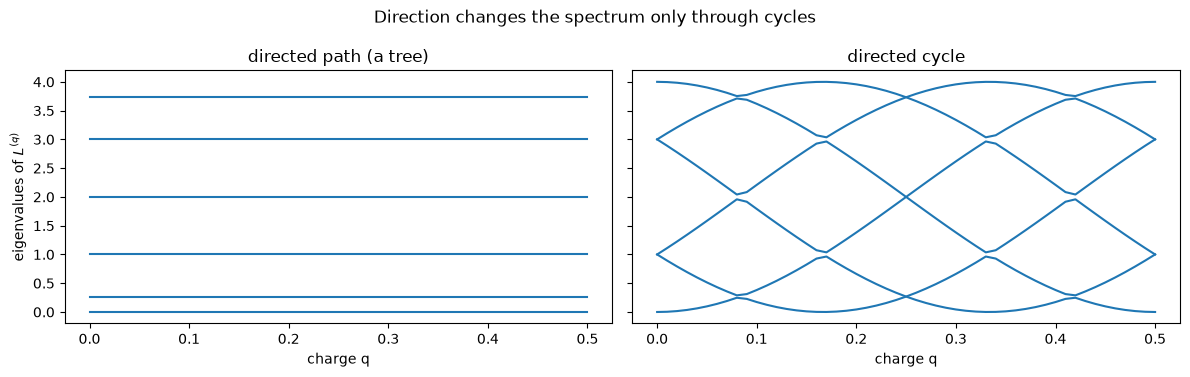

In [2]:
# =====================================================================
# Magnetic Laplacian = Directed Sheaf Laplacian with trivial maps
# =====================================================================
def magnetic_laplacian(directed_edges, n, q):
    A = torch.zeros(n, n)
    for u, v in directed_edges:
        A[u, v] = 1.0
    A_s = ((A + A.T) > 0).to(torch.float64)
    T = torch.exp(1j * 2 * np.pi * q * (A - A.T).to(torch.float64))  # Hermitian phases
    return torch.diag(A_s.sum(1)).to(torch.complex128) - A_s * T


n_demo = 6
cycle = [(u, (u + 1) % n_demo) for u in range(n_demo)]
path = [(u, u + 1) for u in range(n_demo - 1)]

L_q = magnetic_laplacian(cycle, n_demo, q=0.1)
eigvals = torch.linalg.eigvalsh(L_q)
print("--- Basic properties (directed 6-cycle, q = 0.1) ---")
print(f"Hermitian:                {torch.allclose(L_q, L_q.conj().T)}")
print(
    f"Eigenvalues real and >= 0: {bool((eigvals > -1e-10).all())}  min = {eigvals.min():.4f}"
)
L_undirected = magnetic_laplacian(cycle, n_demo, q=0.0)
print(
    f"q = 0 is the undirected Laplacian: {torch.allclose(L_undirected.imag, torch.zeros(n_demo, n_demo, dtype=torch.float64))}"
)

# Reversing every edge conjugates the operator: same spectrum, conjugated eigenvectors.
L_rev = magnetic_laplacian([(v, u) for u, v in cycle], n_demo, q=0.1)
print(f"Reversed graph = complex conjugate: {torch.allclose(L_rev, L_q.conj())}")

# =====================================================================
# Spectrum vs charge q: path (no cycle) vs directed cycle
# =====================================================================
qs = np.linspace(0, 0.5, 51)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, edges, title in [
    (axes[0], path, "directed path (a tree)"),
    (axes[1], cycle, "directed cycle"),
]:
    spectra = np.array(
        [
            torch.linalg.eigvalsh(magnetic_laplacian(edges, n_demo, q)).numpy()
            for q in qs
        ]
    )
    ax.plot(qs, spectra, color="tab:blue")
    ax.set(xlabel="charge q", title=title)
axes[0].set_ylabel("eigenvalues of $L^{(q)}$")
fig.suptitle("Direction changes the spectrum only through cycles")
plt.tight_layout()
plt.show()

The path's eigenvalues are flat lines: on a tree, direction is invisible to the spectrum. The cycle's eigenvalues move with $q$, and at $q > 0$ even the smallest eigenvalue leaves zero, so a directed cycle has no "constant" signal that the Laplacian leaves untouched. The DSNN model learns real maps $\mathcal{F}^{0}$ on top of these phases, so its learned geometry and the graph's directed structure interact through exactly this mechanism.

<a id="4-dataset-pipeline"></a>
# 4. Dataset Pipeline: Information Flows Along the Arrows

We build a directed ring of 120 nodes, $u \to u+1$. Every node draws a hidden class $c_u \in \{0, 1\}$ and observes it through a noisy feature $\mathbf{x}_u$. The **label** of node $v$, however, is the class of its **predecessor**: $y_v = c_{v-1}$.

The task is designed so that direction decides everything:
* the node's own features say nothing about its label (its class and its predecessor's class are independent);
* its **in-neighbour** (the predecessor) determines the label exactly, up to feature noise;
* its **out-neighbour** (the successor) is irrelevant.

An undirected model sees the predecessor and the successor, but cannot tell which is which. When their classes agree it can answer; when they differ (about half the nodes) it must guess.

In [3]:
def random_splits(n: int, train: float = 0.4, val: float = 0.2, seed: int = SEED):
    """Disjoint boolean train/val/test masks over n nodes."""
    g = torch.Generator().manual_seed(seed)
    perm = torch.randperm(n, generator=g)
    n_train, n_val = int(train * n), int(val * n)
    masks = [torch.zeros(n, dtype=torch.bool) for _ in range(3)]
    masks[0][perm[:n_train]] = True
    masks[1][perm[n_train : n_train + n_val]] = True
    masks[2][perm[n_train + n_val :]] = True
    return masks


# =====================================================================
# Directed ring where the label is the predecessor's class
# =====================================================================
set_seed(SEED)
n = 120
hidden_class = torch.randint(0, 2, (n,))
x = F.one_hot(hidden_class, 2).float() + 0.35 * torch.randn(n, 2)
y = hidden_class.roll(1)  # y_v = c_{v-1}

src = torch.arange(n)
edge_index = torch.stack([src, (src + 1) % n])  # u -> u+1 (directed)
train_mask, val_mask, test_mask = random_splits(n)
data = Data(
    x=x,
    y=y,
    edge_index=edge_index,
    train_mask=train_mask,
    val_mask=val_mask,
    test_mask=test_mask,
)

pred_c, succ_c = hidden_class.roll(1), hidden_class.roll(-1)
print("--- Directed toy task ---")
print(data)
print(
    f"P(label == own class):          {(y == hidden_class).float().mean():.3f}  (uninformative)"
)
print(f"P(label == predecessor class):  {(y == pred_c).float().mean():.3f}")
print(
    f"P(label == successor class):    {(y == succ_c).float().mean():.3f}  (uninformative)"
)
print(
    f"Nodes whose two neighbours agree: {(pred_c == succ_c).float().mean():.3f}"
    "  -> ceiling of an undirected model ~ agree + 0.5 * (1 - agree)"
)

--- Directed toy task ---
Data(x=[120, 2], edge_index=[2, 120], y=[120], train_mask=[120], val_mask=[120], test_mask=[120])
P(label == own class):          0.533  (uninformative)
P(label == predecessor class):  1.000
P(label == successor class):    0.633  (uninformative)
Nodes whose two neighbours agree: 0.633  -> ceiling of an undirected model ~ agree + 0.5 * (1 - agree)


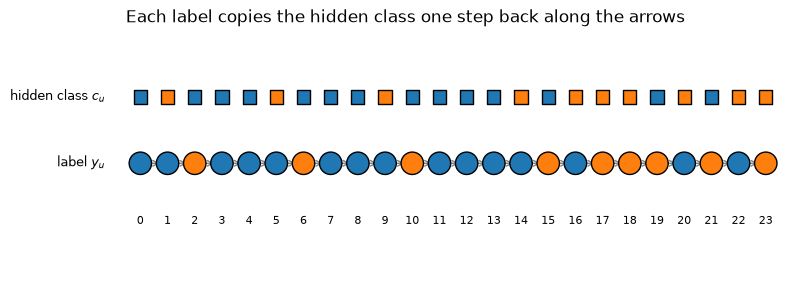

In [4]:
# =====================================================================
# Draw a stretch of the ring with its arrows
# =====================================================================
angles = np.linspace(0, 2 * np.pi, n, endpoint=False)
pos = np.stack([np.cos(angles), np.sin(angles)], 1)
shown = range(0, 24)
fig, ax = plt.subplots(figsize=(10, 3.2))
xs = np.arange(len(shown))
for i in xs[:-1]:
    ax.annotate(
        "",
        xy=(i + 1 - 0.18, 0),
        xytext=(i + 0.18, 0),
        arrowprops=dict(arrowstyle="->", color="gray"),
    )
ax.scatter(
    xs,
    np.zeros_like(xs),
    s=260,
    c=[f"C{int(y[u])}" for u in shown],
    edgecolors="k",
    zorder=3,
)
ax.scatter(
    xs,
    np.full_like(xs, 0.35, dtype=float),
    s=90,
    marker="s",
    c=[f"C{int(hidden_class[u])}" for u in shown],
    edgecolors="k",
)
for i, u in zip(xs, shown, strict=True):
    ax.text(i, -0.32, str(u), ha="center", fontsize=8)
ax.text(-1.3, 0.35, "hidden class $c_u$", ha="right", va="center", fontsize=9)
ax.text(-1.3, 0.0, "label $y_u$", ha="right", va="center", fontsize=9)
ax.set(xlim=(-4.5, len(shown)), ylim=(-0.6, 0.7))
ax.axis("off")
ax.set_title("Each label copies the hidden class one step back along the arrows")
plt.show()

<a id="5-model-construction"></a>
# 5. Model Construction

We use diagonal restriction maps ($d = 2$) everywhere and compare:
* `DirectedNSDModel` with fixed $\alpha \in \{0, 0.25, 0.5, 0.75, 1\}$;
* `DirectedNSDModel` with `learn_alpha=True`, initialized at $\alpha = 0.5$;
* the undirected `NSDModel` on the **symmetrized** ring, as the direction-blind baseline.

In [5]:
assert isinstance(data, Data)
assert isinstance(data.x, torch.Tensor)
assert isinstance(data.y, torch.Tensor)
assert isinstance(data.edge_index, torch.Tensor)
# =====================================================================
# Model factories
# =====================================================================
undirected_edge_index = to_undirected(edge_index, num_nodes=n)


def directed_model(alpha, learn_alpha=False):
    return DirectedNSDModel(
        2,
        2,
        stalk_dim=2,
        hidden_dim=8,
        num_layers=2,
        variant=DirectedNSDVariant.DIAGONAL,
        alpha=alpha,
        learn_alpha=learn_alpha,
    )


def undirected_model():
    return NSDModel(
        2, 2, stalk_dim=2, hidden_dim=8, num_layers=2, variant=NSDVariant.DIAGONAL
    )


demo = directed_model(0.5)
with torch.no_grad():
    out = demo(data.x, data.edge_index)
print(
    f"Directed logits: {tuple(out.shape)} | parameters: {sum(p.numel() for p in demo.parameters()):,}"
)
print(
    f"alpha of each layer: {[round(float(layer.alpha), 2) for layer in demo.layers]} "
    f"(requires_grad={demo.layers[0].alpha.requires_grad})"
)

Directed logits: (120, 2) | parameters: 920
alpha of each layer: [0.5, 0.5] (requires_grad=False)


<a id="6-training-pipeline"></a>
# 6. Training Pipeline

Each configuration is trained with three seeds using masked cross-entropy and validation-based model selection.

In [6]:
assert isinstance(data, Data)
assert isinstance(data.x, torch.Tensor)
assert isinstance(data.y, torch.Tensor)
assert isinstance(data.edge_index, torch.Tensor)


# =====================================================================
# Masked training with validation-based model selection
# =====================================================================
def accuracy(logits: torch.Tensor, y: torch.Tensor, mask: torch.Tensor) -> float:
    return (logits[mask].argmax(-1) == y[mask]).float().mean().item()


def train_model(
    model, predict, data, epochs=150, lr=0.01, weight_decay=5e-4, extra_loss=None
):
    """Adam on masked cross-entropy; restores the state with the lowest validation loss.

    Args:
        model: the network to optimize.
        predict: zero-argument callable returning logits [N, C] for the whole graph.
        data: PyG Data with y, train_mask, val_mask, test_mask.
        epochs: number of full-batch optimization steps.
        lr: Adam learning rate.
        weight_decay: Adam L2 penalty.
        extra_loss: optional callable(epoch) -> scalar added to the loss (e.g. a KL term).

    Returns:
        (history, test_accuracy) where history holds one dict per epoch.
    """
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history, best_val, best_state = [], float("inf"), None
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        logits = predict()
        loss = F.cross_entropy(logits[data.train_mask], data.y[data.train_mask])
        if extra_loss is not None:
            loss = loss + extra_loss(epoch)
        assert torch.isfinite(loss), "non-finite training loss"
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_logits = predict()
            val_loss = F.cross_entropy(
                val_logits[data.val_mask], data.y[data.val_mask]
            ).item()
        history.append(
            {
                "train_loss": loss.item(),
                "val_loss": val_loss,
                "val_acc": accuracy(val_logits, data.y, data.val_mask),
            }
        )
        if val_loss < best_val:
            best_val, best_state = val_loss, copy.deepcopy(model.state_dict())

    assert best_state is not None, "No finite validation score; check epochs and loss"
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        test_acc = accuracy(predict(), data.y, data.test_mask)
    return history, test_acc


def plot_history(history, title):
    """Training/validation curves of one run."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
    axes[0].plot([h["train_loss"] for h in history], label="train loss")
    axes[0].plot([h["val_loss"] for h in history], label="validation loss")
    axes[0].set(xlabel="epoch", ylabel="cross-entropy", title=title)
    axes[0].legend()
    axes[1].plot([h["val_acc"] for h in history], color="tab:green")
    axes[1].set(
        xlabel="epoch",
        ylabel="validation accuracy",
        ylim=(0, 1.02),
        title="Validation accuracy",
    )
    plt.tight_layout()
    plt.show()


# =====================================================================
# Train the alpha sweep and the undirected baseline
# =====================================================================
SEEDS = (0, 1, 2)
alphas = [0.0, 0.25, 0.5, 0.75, 1.0]
sweep, trained_forward = {}, None
for a in alphas:
    accs = []
    for seed in SEEDS:
        set_seed(seed)
        model = directed_model(a)
        _, acc = train_model(model, lambda m=model: m(data.x, data.edge_index), data)
        accs.append(acc)
        if a == 1.0 and seed == 0:
            trained_forward = model
    sweep[a] = accs

undirected_accs = []
for seed in SEEDS:
    set_seed(seed)
    model = undirected_model()
    _, acc = train_model(model, lambda m=model: m(data.x, undirected_edge_index), data)
    undirected_accs.append(acc)

print("--- Test accuracy (3 seeds) ---")
for a, accs in sweep.items():
    print(f"Directed NSD, alpha = {a:<4}: {np.mean(accs):.3f} +/- {np.std(accs):.3f}")
print(
    f"Undirected NSD (symmetrized): {np.mean(undirected_accs):.3f} +/- {np.std(undirected_accs):.3f}"
)

--- Test accuracy (3 seeds) ---
Directed NSD, alpha = 0.0 : 0.562 +/- 0.106
Directed NSD, alpha = 0.25: 0.903 +/- 0.079
Directed NSD, alpha = 0.5 : 0.917 +/- 0.045
Directed NSD, alpha = 0.75: 0.965 +/- 0.020
Directed NSD, alpha = 1.0 : 0.958 +/- 0.034
Undirected NSD (symmetrized): 0.694 +/- 0.026


<a id="7-interpretation"></a>
# 7. Interpreting Direction

<a id="alpha-sweep"></a>
### 7.1 Sweeping the Direction Weight

Plotting accuracy against $\alpha$ turns the table into a picture of *where the information is*. The label lives in the in-neighbours, so the forward channel $\mathbf{m}^{\rightarrow}$ must be available. The undirected baseline sees both neighbours without knowing which is which, so it is capped by the nodes whose two neighbours disagree.

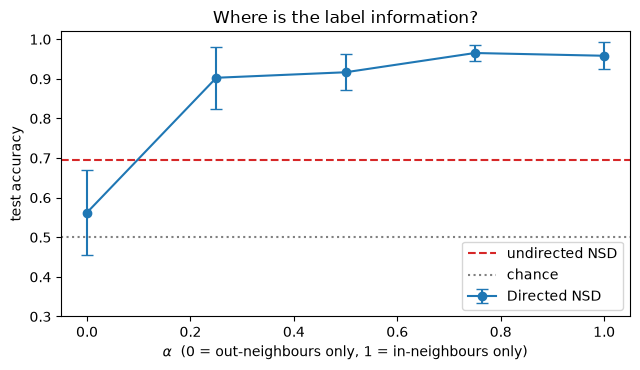

In [7]:
# =====================================================================
# Accuracy as a function of alpha
# =====================================================================
means = [np.mean(sweep[a]) for a in alphas]
stds = [np.std(sweep[a]) for a in alphas]
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.errorbar(alphas, means, yerr=stds, marker="o", capsize=4, label="Directed NSD")
ax.axhline(np.mean(undirected_accs), color="tab:red", ls="--", label="undirected NSD")
ax.axhline(0.5, color="gray", ls=":", label="chance")
ax.set(
    xlabel=r"$\alpha$  (0 = out-neighbours only, 1 = in-neighbours only)",
    ylabel="test accuracy",
    ylim=(0.3, 1.02),
    title="Where is the label information?",
)
ax.legend()
plt.tight_layout()
plt.show()

**What the sweep shows.** Accuracy is at chance for $\alpha = 0$ and close to perfect for **every** $\alpha > 0$: a step, not a slope. The reason is in the operator of Section 3.1. Each direction has its own stalk transforms $W_1^{\rightarrow}, W_2^{\rightarrow}$ and $W_1^{\leftarrow}, W_2^{\leftarrow}$, so the network can rescale either channel at will, and a fixed $\alpha \in (0, 1)$ is just a constant factor that training absorbs. What $\alpha$ really decides is which channels **exist**: $\alpha = 0$ removes the informative in-neighbour channel, and $\alpha = 1$ removes the out-neighbour channel. The undirected model lands near its ceiling: it solves the nodes whose neighbours agree and guesses on the rest.

<a id="learned-alpha"></a>
### 7.2 Learning the Direction Weight

On real data we rarely know which direction matters, which is why `learn_alpha=True` exists. We start every layer at the neutral $\alpha = 0.5$ and record its value during training. Given what the sweep showed, we should *not* expect $\alpha$ to travel far: the per-direction weights can do the same job. Note that $\alpha$ is an unconstrained scalar: values outside $[0, 1]$ would mean the model *subtracts* one direction instead of averaging the two.

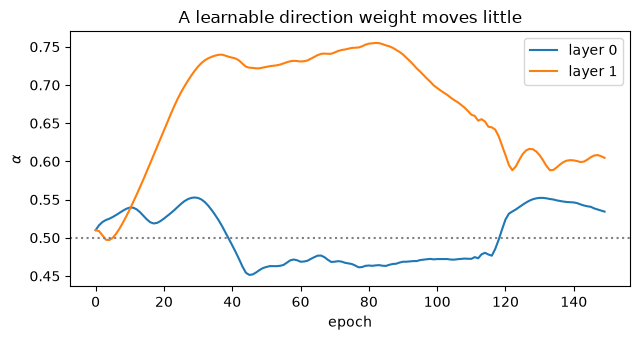

Final alphas: [0.534 0.605] | test accuracy: 0.854


In [8]:
assert isinstance(data, Data)
assert isinstance(data.x, torch.Tensor)
assert isinstance(data.y, torch.Tensor)
assert isinstance(data.edge_index, torch.Tensor)
# =====================================================================
# Track a learnable alpha during training
# =====================================================================
set_seed(0)
learner = directed_model(0.5, learn_alpha=True)
optimizer = torch.optim.Adam(learner.parameters(), lr=0.01, weight_decay=5e-4)
trajectory = []
for _ in range(150):
    learner.train()
    optimizer.zero_grad()
    loss = F.cross_entropy(learner(data.x, data.edge_index)[train_mask], y[train_mask])
    loss.backward()
    optimizer.step()
    trajectory.append([float(layer.alpha) for layer in learner.layers])

trajectory = np.array(trajectory)
fig, ax = plt.subplots(figsize=(6.5, 3.5))
for i in range(trajectory.shape[1]):
    ax.plot(trajectory[:, i], label=f"layer {i}")
ax.axhline(0.5, color="gray", ls=":")
ax.set(
    xlabel="epoch",
    ylabel=r"$\alpha$",
    title="A learnable direction weight moves little",
)
ax.legend()
plt.tight_layout()
plt.show()
learner.eval()
with torch.no_grad():
    print(
        f"Final alphas: {np.round(trajectory[-1], 3)} | test accuracy: "
        f"{accuracy(learner(data.x, data.edge_index), y, test_mask):.3f}"
    )

**Reading the trajectory.** The learned weights stay close to their initial value, with at most a moderate drift towards the forward channel. A learned $\alpha$ is therefore a weak signal of which direction matters: when it barely moves, the per-direction weights are doing the work. The sweep with a fixed $\alpha \in \{0, 1\}$, which removes one channel entirely, and the reversal test below are more reliable probes of where the information is.

<a id="reversal-test"></a>
### 7.3 Reversing the Arrows

The last test is a counterfactual on the **graph**, not the parameters. We take the trained $\alpha = 1$ model and feed it the ring with every edge reversed. Each node now hears its *successor* through the channel it learned to treat as its predecessor. If the model really uses direction, accuracy should fall to chance. An undirected model is unaffected by construction.

In [9]:
assert isinstance(data, Data)
assert isinstance(data.x, torch.Tensor)
assert isinstance(data.y, torch.Tensor)
assert isinstance(data.edge_index, torch.Tensor)
# =====================================================================
# Counterfactual: reverse every edge at test time
# =====================================================================
assert trained_forward is not None
trained_forward.eval()
with torch.no_grad():
    acc_true = accuracy(trained_forward(data.x, data.edge_index), y, test_mask)
    acc_rev = accuracy(trained_forward(data.x, data.edge_index.flip(0)), y, test_mask)
print("--- Directed NSD (alpha = 1) ---")
print(f"Original arrows: {acc_true:.3f}")
print(f"Reversed arrows: {acc_rev:.3f}")

--- Directed NSD (alpha = 1) ---
Original arrows: 0.958
Reversed arrows: 0.521


<a id="8-exercises"></a>
# 8. Configuration, Reproducibility, and Exercises

**Using it on real data.** In the experiment runner, pass `--directed` to keep the stored edge directions (the default pipeline symmetrizes), together with `--model.type directed_nsd`:

```bash
sheaf run --preset cora_directed_nsd_general               # sets --directed for you
sheaf run --preset chameleon_filtered --model.type directed_nsd --directed --model.learn-alpha
```

Record the seed, the variant, $\alpha$ (or whether it was learned), the depth, and whether the graph was symmetrized. Reversing or symmetrizing the edges is a cheap ablation that tells you whether a dataset's direction carries signal at all.

**Key takeaways**
* An orientation chosen to write the coboundary is bookkeeping; modelling direction needs an operator that changes when edges are reversed.
* The repository's Directed NSD separates in- and out-neighbour transport and blends them with $\alpha$, which makes the importance of each direction directly measurable.
* The complex-valued Directed Sheaf Laplacian stays Hermitian and positive semi-definite, generalizes the magnetic Laplacian, and "sees" direction through the cycles of the graph.

### Hands-on Exercises
1. **Two hops back.** Change the labels to $y_v = c_{v-2}$. Which depth and which $\alpha$ are now needed?
2. **Mixed information.** Make the label depend on both neighbours, for example $y_v = c_{v-1} \oplus c_{v+1}$ (XOR). Which $\alpha$ is best now, and can the undirected model solve it?
3. **Shortcuts.** Add 20 random directed chords to the ring and repeat the reversal test. How robust is the learned direction?
4. **Charge.** In Section 3.3, find the values of $q$ for which the directed 6-cycle has a zero eigenvalue again. Relate them to the flux $e^{i 2\pi q n}$.